# Fase 5: políticas P0 y P1
P0 riega por calendario. P1 predice el estrés contrafactual sin riego y consulta su umbral elegido en validación.

        agua_mm  drenaje_mm  perdida_rendimiento      costo
policy                                                     
P0       200.00  558.536075             0.550822  65.082153
P1       332.25  606.101027             0.017129  18.325358


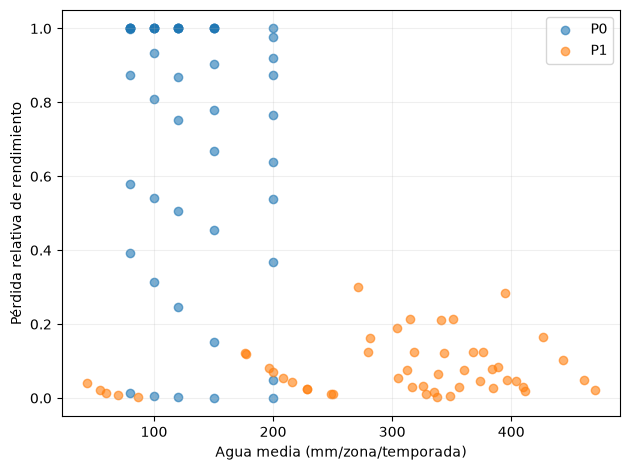

In [1]:
# Preparar imports y resolver la carpeta de resultados.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'results').exists(): ROOT = ROOT.parent
# Resumir los resultados finales de las políticas P0 y P1.
results = pd.read_csv(ROOT / 'results/metricas_politicas.csv')
print(results.groupby('policy')[['agua_mm','drenaje_mm','perdida_rendimiento','costo']].mean())
# Mostrar candidatos ajustados en validación, separados del test.
frontier = pd.read_csv(ROOT / 'results/frontera_validacion.csv')
for name, group in frontier.groupby('policy'):
    plt.scatter(group.agua_mm, group.perdida_rendimiento, label=name, alpha=.6)
plt.xlabel('Agua media (mm/zona/temporada)'); plt.ylabel('Pérdida relativa de rendimiento')
plt.legend(); plt.grid(alpha=.2); plt.tight_layout()